# Turbofan RUL Prediction — Exploratory Analysis

Dataset: NASA C-MAPSS Turbofan Engine Degradation Simulation (Saxena & Goebel, 2008). We start with **FD001** — 100 training engines, 100 test engines, one operating condition, one fault mode (HPC degradation).

The product question: given an engine's sensor history, **how many operating cycles remain before failure?** Before modeling, we need to know which sensors actually carry degradation signal — and which are just noise or constants.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
DATA, FIG = "../data", "../reports/figures"
os.makedirs(FIG, exist_ok=True)
COLS = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
SENSORS = [f"s{i}" for i in range(1, 22)]
def load(name):
    return pd.read_csv(f"{DATA}/{name}", sep=r"\s+", header=None, names=COLS)
train = load("train_FD001.txt"); test = load("test_FD001.txt")
rul_test = pd.read_csv(f"{DATA}/RUL_FD001.txt", header=None, names=["rul"])
print("train:", train.shape, "| test:", test.shape, "| rul rows:", len(rul_test))
print("train engines:", train.unit.nunique(), "| test engines:", test.unit.nunique())
print("columns:", len(COLS))
train.head(3).to_string()

train: (20631, 26) | test: (13096, 26) | rul rows: 100
train engines: 100 | test engines: 100
columns: 26


'   unit  cycle     op1     op2    op3      s1      s2       s3       s4     s5     s6      s7       s8       s9  s10    s11     s12      s13      s14     s15   s16  s17   s18    s19    s20      s21\n0     1      1 -0.0007 -0.0004  100.0  518.67  641.82  1589.70  1400.60  14.62  21.61  554.36  2388.06  9046.19  1.3  47.47  521.66  2388.02  8138.62  8.4195  0.03  392  2388  100.0  39.06  23.4190\n1     1      2  0.0019 -0.0003  100.0  518.67  642.15  1591.82  1403.14  14.62  21.61  553.75  2388.04  9044.07  1.3  47.49  522.28  2388.07  8131.49  8.4318  0.03  392  2388  100.0  39.00  23.4236\n2     1      3 -0.0043  0.0003  100.0  518.67  642.35  1587.99  1404.20  14.62  21.61  554.26  2388.08  9052.94  1.3  47.27  522.42  2388.03  8133.23  8.4178  0.03  390  2388  100.0  38.95  23.3442'

## 1. Engine lifespans

Each row is one operating cycle of one engine. Engines fail at different ages — the spread of lifespans is the first thing a maintenance planner cares about.

engines: 100 | lifespan: min=128, max=362, mean=206, median=199 cycles


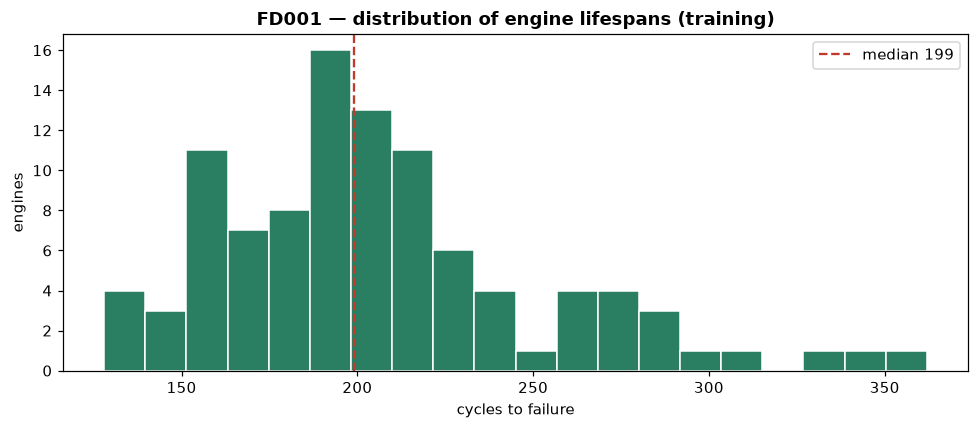

'count    100.0\nmean     206.3\nstd       46.3\nmin      128.0\n25%      177.0\n50%      199.0\n75%      229.2\nmax      362.0'

In [2]:
life = train.groupby("unit").cycle.max()
print(f"engines: {len(life)} | lifespan: min={life.min()}, max={life.max()}, "
      f"mean={life.mean():.0f}, median={life.median():.0f} cycles")
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(life, bins=20, color="#2a7f62", edgecolor="white")
ax.axvline(life.median(), color="#c0392b", ls="--", lw=1.5,
           label=f"median {life.median():.0f}")
ax.set_title("FD001 — distribution of engine lifespans (training)", fontweight="bold")
ax.set_xlabel("cycles to failure"); ax.set_ylabel("engines"); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIG}/01_lifespans.png", dpi=120); plt.show()
life.describe().round(1).to_string()

## 2. Do the sensors show degradation?

Pick three engines (short, medium, long life) and watch four sensors across their whole lives. A sensor with prognostics value should *trend* as failure approaches — not just wiggle.

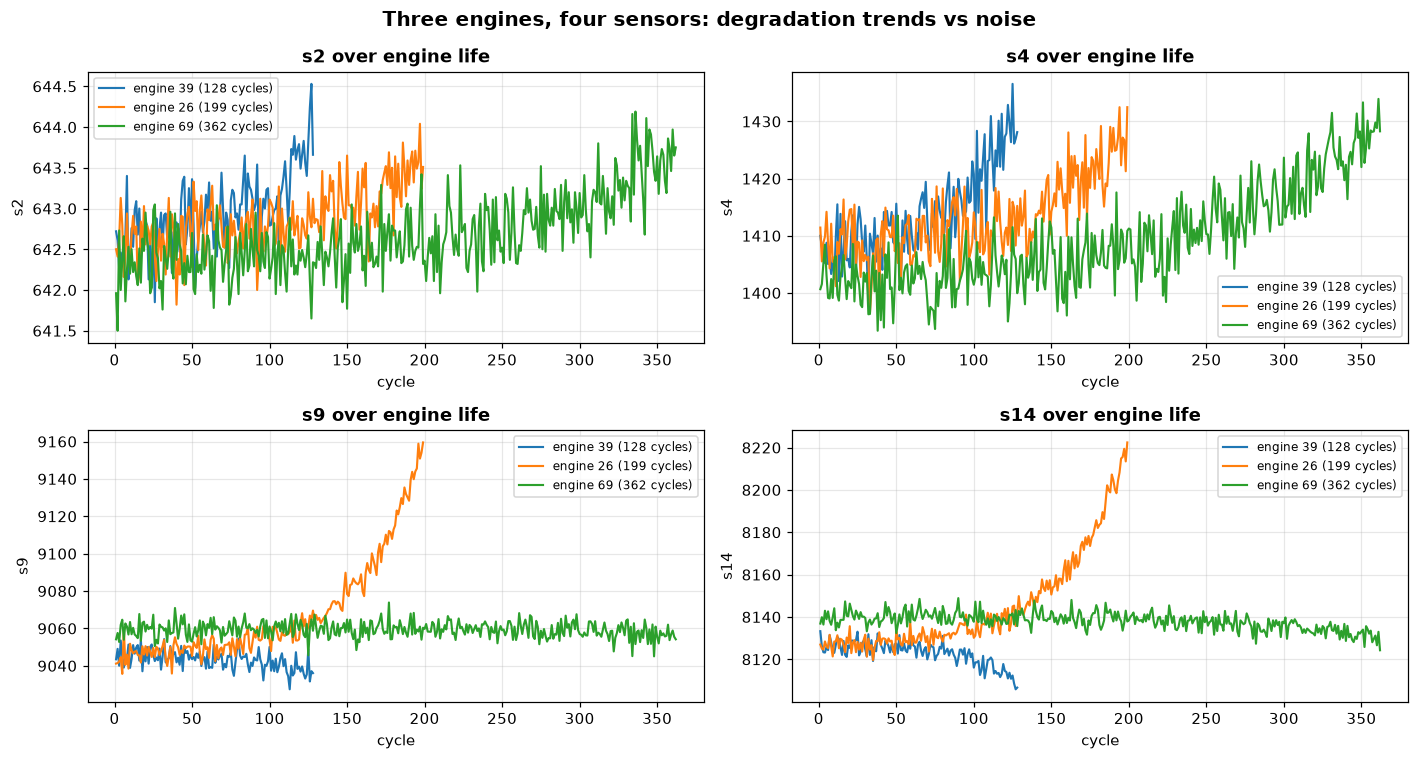

In [3]:
units = [life.idxmin(), life.sub(life.median()).abs().idxmin(), life.idxmax()]
show = ["s2", "s4", "s9", "s14"]
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=False)
for ax, s in zip(axes.ravel(), show):
    for u in units:
        d = train[train.unit == u]
        ax.plot(d.cycle.values, d[s].values, lw=1.4,
                label=f"engine {u} ({d.cycle.max()} cycles)")
    ax.set_title(f"{s} over engine life", fontweight="bold")
    ax.set_xlabel("cycle"); ax.set_ylabel(s); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle("Three engines, four sensors: degradation trends vs noise",
             fontsize=13, fontweight="bold")
fig.tight_layout(); fig.savefig(f"{FIG}/02_sensor_trends.png", dpi=120); plt.show()

## 3. Which sensors actually move?

Two cheap, honest screens across all 100 engines: (a) is the sensor constant (zero variance — dead weight for any model), and (b) does it correlate with elapsed cycles (a trend toward failure)?

/home/hatch/workspace/portfolio/02-nasa-turbofan-rul/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/hatch/workspace/portfolio/02-nasa-turbofan-rul/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


constant sensors: ['s1', 's5', 's10', 's16', 's18', 's19']
informative (|trend corr| > 0.5): ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


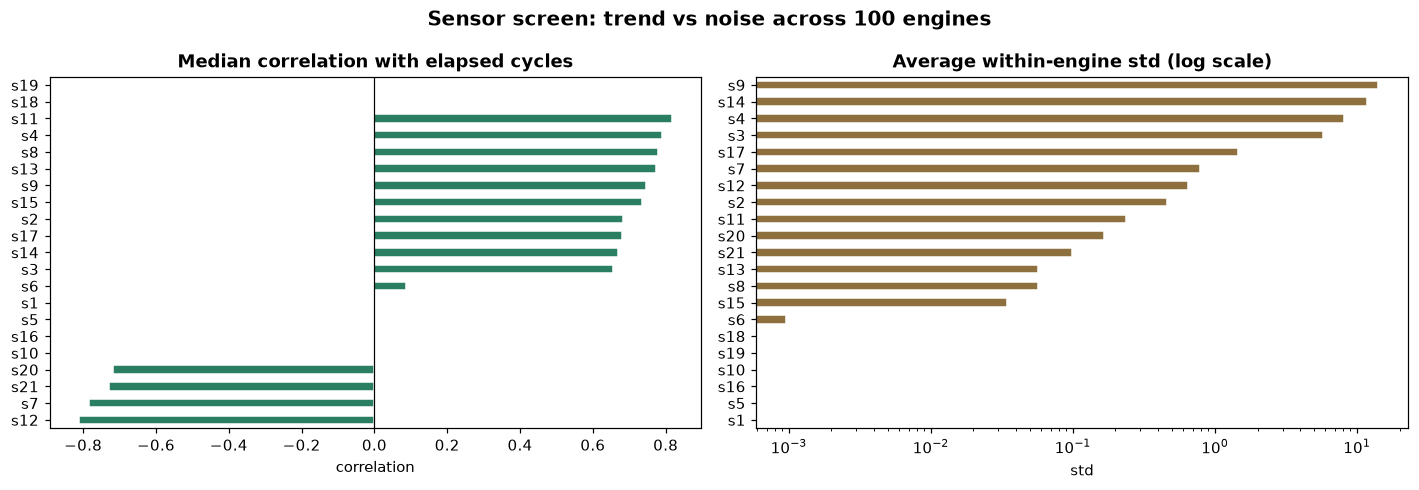

'     avg_std  trend_corr  constant\ns1     0.000       0.000      True\ns2     0.463       0.683     False\ns3     5.789       0.654     False\ns4     8.118       0.790     False\ns5     0.000       0.000      True\ns6     0.001       0.087     False\ns7     0.786      -0.783     False\ns8     0.057       0.778     False\ns9    14.189       0.747     False\ns10    0.000       0.000      True\ns11    0.237       0.816     False\ns12    0.648      -0.811     False\ns13    0.057       0.774     False\ns14   11.804       0.670     False\ns15    0.034       0.735     False\ns16    0.000       0.000      True\ns17    1.451       0.681     False\ns18    0.000         NaN      True\ns19    0.000         NaN      True\ns20    0.166      -0.717     False\ns21    0.100      -0.730     False'

In [4]:
var = train.groupby("unit")[SENSORS].std().mean()          # avg within-engine std
corr = train.groupby("unit")[SENSORS + ["cycle"]].apply(
    lambda d: d[SENSORS].corrwith(d["cycle"])).median()     # median trend corr
screen = pd.DataFrame({"avg_std": var, "trend_corr": corr})
screen["constant"] = screen.avg_std < 1e-6
print(f"constant sensors: {screen[screen.constant].index.tolist()}")
print(f"informative (|trend corr| > 0.5): "
      f"{screen[~screen.constant & (screen.trend_corr.abs() > 0.5)].index.tolist()}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
screen.sort_values("trend_corr").trend_corr.plot.barh(ax=axes[0], color="#2a7f62",
                                                      edgecolor="white")
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Median correlation with elapsed cycles", fontweight="bold")
axes[0].set_xlabel("correlation")
screen.sort_values("avg_std").avg_std.plot.barh(ax=axes[1], color="#8e6f3e",
                                                 edgecolor="white", logx=True)
axes[1].set_title("Average within-engine std (log scale)", fontweight="bold")
axes[1].set_xlabel("std")
fig.suptitle("Sensor screen: trend vs noise across 100 engines", fontsize=13,
             fontweight="bold")
fig.tight_layout(); fig.savefig(f"{FIG}/03_sensor_screen.png", dpi=120); plt.show()
screen.round(3).to_string()

## 4. Operating conditions

FD001 was simulated under a *single* operating condition — worth verifying, because FD002/FD004 have six regimes and need regime-normalized features (a stretch goal for the modeling notebook).

In [5]:
ops = train.groupby("unit")[["op1", "op2", "op3"]].agg(["mean", "std"])
print("Within-engine std of operational settings (should be ~0 in FD001):")
print(ops.xs("std", axis=1, level=1).mean().round(6).to_string())
print("\nDistinct setting combinations in FD001:",
      train[["op1", "op2", "op3"]].drop_duplicates().shape[0])

Within-engine std of operational settings (should be ~0 in FD001):
op1    0.002187
op2    0.000290
op3    0.000000

Distinct setting combinations in FD001: 1423


## 5. Building the RUL label

The dataset gives us cycles, not RUL — so we construct it: `RUL = max_cycle − cycle` per engine. But engines spend most of their life healthy, with no degradation signal. The standard practice (and the honest one) is a **piecewise-linear** target: RUL is capped at 125 cycles early in life, then decreases linearly. This stops the model from chasing noise in the healthy phase.

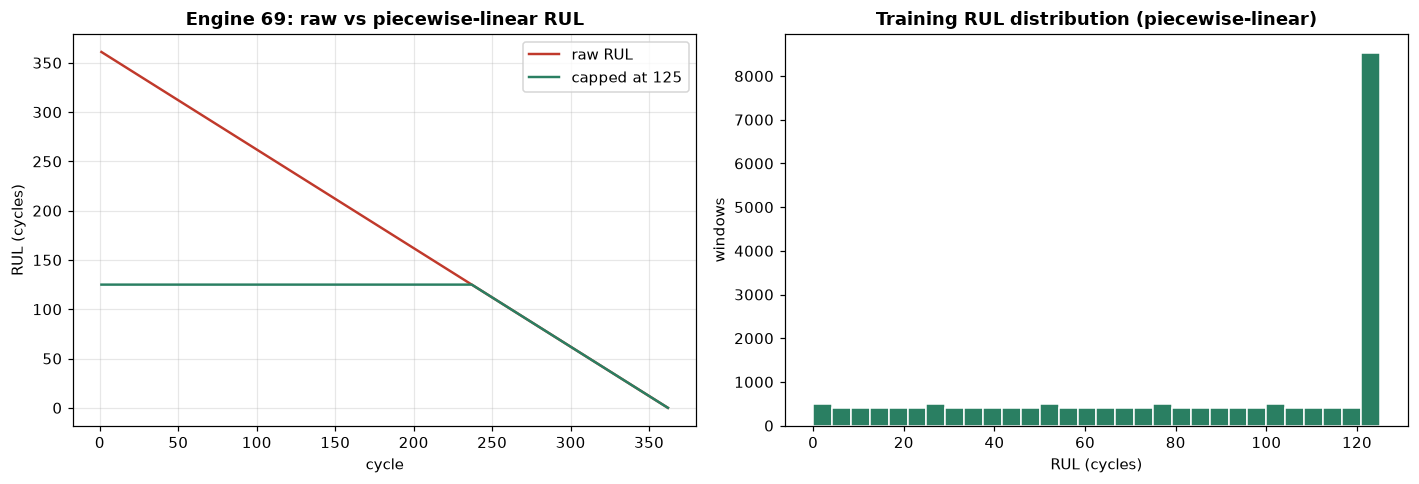

RUL cap: 125 | share of capped (healthy-phase) rows: 39.4%


In [6]:
RUL_MAX = 125
u = life.idxmax()
d = train[train.unit == u].copy()
d["rul_raw"] = d.cycle.max() - d.cycle
d["rul"] = d.rul_raw.clip(upper=RUL_MAX)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(d.cycle, d.rul_raw, color="#c0392b", lw=1.6, label="raw RUL")
axes[0].plot(d.cycle, d.rul, color="#2a7f62", lw=1.6, label=f"capped at {RUL_MAX}")
axes[0].set_title(f"Engine {u}: raw vs piecewise-linear RUL", fontweight="bold")
axes[0].set_xlabel("cycle"); axes[0].set_ylabel("RUL (cycles)")
axes[0].legend(); axes[0].grid(alpha=0.3)
rul_all = train.groupby("unit").apply(
    lambda x: (x.cycle.max() - x.cycle).clip(upper=RUL_MAX), include_groups=False)
axes[1].hist(rul_all.values, bins=30, color="#2a7f62", edgecolor="white")
axes[1].set_title("Training RUL distribution (piecewise-linear)", fontweight="bold")
axes[1].set_xlabel("RUL (cycles)"); axes[1].set_ylabel("windows")
fig.tight_layout(); fig.savefig(f"{FIG}/04_rul_label.png", dpi=120); plt.show()
print(f"RUL cap: {RUL_MAX} | share of capped (healthy-phase) rows: "
      f"{(rul_all.values == RUL_MAX).mean():.1%}")

## 6. The test set: truncated engines

Test engines are cut off *before* failure — that's the actual prediction task. The separate `RUL_FD001.txt` gives the ground truth for each test engine's final observed cycle.

test engines: 100 | observed cycles: min=31, max=303, mean=131
ground-truth RUL at truncation: min=7, max=145, mean=76


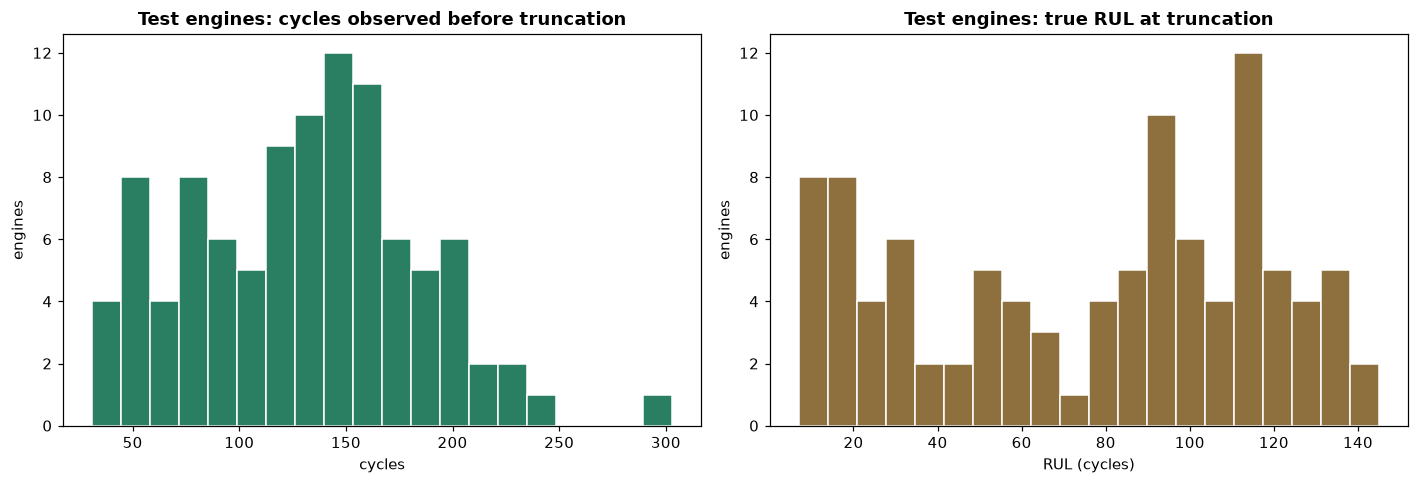

In [7]:
test_life = test.groupby("unit").cycle.max()
print(f"test engines: {len(test_life)} | observed cycles: "
      f"min={test_life.min()}, max={test_life.max()}, mean={test_life.mean():.0f}")
print(f"ground-truth RUL at truncation: min={rul_test.rul.min()}, "
      f"max={rul_test.rul.max()}, mean={rul_test.rul.mean():.0f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(test_life, bins=20, color="#2a7f62", edgecolor="white")
axes[0].set_title("Test engines: cycles observed before truncation", fontweight="bold")
axes[0].set_xlabel("cycles"); axes[0].set_ylabel("engines")
axes[1].hist(rul_test.rul, bins=20, color="#8e6f3e", edgecolor="white")
axes[1].set_title("Test engines: true RUL at truncation", fontweight="bold")
axes[1].set_xlabel("RUL (cycles)"); axes[1].set_ylabel("engines")
fig.tight_layout(); fig.savefig(f"{FIG}/05_test_truncation.png", dpi=120); plt.show()

## 7. Takeaways → modeling

1. **~7 of 21 sensors are constant** in FD001 — drop them before modeling.
2. **~14 sensors trend with age** — the degradation signal is real and visible.
3. **Single operating condition** — no regime normalization needed for FD001 (keep the technique in the back pocket for FD002/FD004).
4. **Piecewise-linear RUL (cap 125)** keeps the model honest in the healthy phase.
5. Test engines are truncated mid-life — the model must extrapolate, not just interpolate.

Next: `02_modeling.ipynb` — sliding-window features, model comparison, RMSE + the PHM asymmetric score (late predictions cost more than early ones — because in maintenance, they do).